# 📊 Análisis de Sentimiento en Reseñas de Clientes — WeLoveReviews
## 1. Objetivos y Contexto de Negocio
* **Cliente:** WeLoveReviews / Harbor House Café.
* **Pregunta de negocio:** La cuenta tiene una puntuación promedio de **~4.5 / 5 estrellas**. ¿El sentimiento expresado en las reseñas escritas realmente coincide con esa alta puntuación, o existen discrepancias ocultas?
* **Objetivo de este Notebook:** 
  1. Explorar el dataset de 500 reseñas (`data/raw/reviews.csv`).
  2. Evaluar la calidad y características del texto (EDA).
  3. Formular una estrategia de limpieza y justificar los siguientes pasos antes de incorporar el modelo NLP.

### 2. Carga del Dataset y Verificación Inicial
Importamos las librerías base de análisis y cargamos las reseñas sin procesar desde `data/raw/reviews.csv`.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)
df = pd.read_csv("../data/raw/reviews.csv")
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas\n")
df.info()
df.head()

Dimensiones del dataset: 500 filas y 3 columnas

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    500 non-null    int64
 1   rating       500 non-null    int64
 2   review_text  500 non-null    str  
dtypes: int64(2), str(1)
memory usage: 11.8 KB


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great ...
1,2,5,Tried Harbor House Café after seeing it recomm...
2,3,5,Tried Harbor House Café after seeing it recomm...
3,4,5,Visited Harbor House Café last weekend. The st...
4,5,5,Grabbed a quick coffee at Harbor House Café th...


### 3. Distribución de Calificaciones (`rating`)
Analizamos la frecuencia de cada puntuación en estrellas y calculamos el promedio real del negocio para contrastarlo con el valor de referencia (~4.5 estrellas).

⭐ Calificación promedio real: 4.50 / 5.0

Distribución por estrellas:


,Cantidad,Porcentaje (%)
rating,,
5,360,72.0
4,72,14.4
3,38,7.6
2,18,3.6
1,12,2.4


C:\Users\balsa\AppData\Local\Temp\ipykernel_33284\3783891429.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="rating", palette="Blues_r", order=[5, 4, 3, 2, 1], ax=ax)


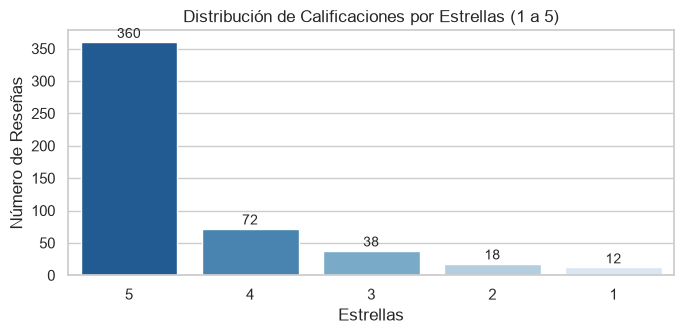

In [13]:
promedio_rating = df["rating"].mean()
print(f"⭐ Calificación promedio real: {promedio_rating:.2f} / 5.0")
rating_counts = df["rating"].value_counts().sort_index(ascending=False)
rating_pct = (df["rating"].value_counts(normalize=True).sort_index(ascending=False) * 100).round(2)
resumen_ratings = pd.DataFrame({
    "Cantidad": rating_counts,
    "Porcentaje (%)": rating_pct
})
print("\nDistribución por estrellas:")
display(resumen_ratings)
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.countplot(data=df, x="rating", palette="Blues_r", order=[5, 4, 3, 2, 1], ax=ax)
ax.set_title("Distribución de Calificaciones por Estrellas (1 a 5)")
ax.set_xlabel("Estrellas")
ax.set_ylabel("Número de Reseñas")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="baseline", fontsize=10, xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()

### 4. Longitud de las Reseñas y Exploración Textual
Calculamos la longitud en caracteres y en palabras de cada reseña para evaluar su extensión y asegurar que se ajustan al límite de procesamiento de modelos tipo BERT. Además, extraemos una muestra cualitativa para familiarizarnos con el lenguaje y estilo de los clientes.


Estadísticas descriptivas de longitud:


,char_length,word_count
count,500.0,500.0
mean,170.2,29.1
std,27.1,4.8
min,86.0,14.0
25%,155.0,26.0
50%,173.0,29.0
75%,189.0,32.0
max,230.0,42.0


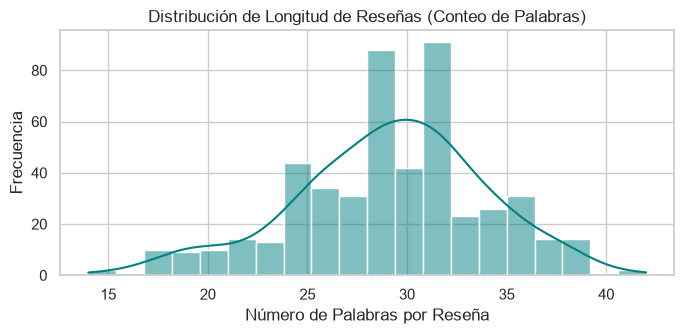


--- Muestra de reseñas por calificación ---

[Rating: 5 estrellas]:
"Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit."

[Rating: 3 estrellas]:
"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop."

[Rating: 1 estrellas]:
"Regular customer at Harbor House Café here. The portions were way too small for the price. Nobody checked on us the entire meal. Not sure I'll be returning."


In [14]:
df["char_length"] = df["review_text"].apply(len)
df["word_count"] = df["review_text"].apply(lambda x: len(x.split()))

print("Estadísticas descriptivas de longitud:")
display(df[["char_length", "word_count"]].describe().round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(df["word_count"], bins=20, kde=True, color="teal", ax=ax)
ax.set_title("Distribución de Longitud de Reseñas (Conteo de Palabras)")
ax.set_xlabel("Número de Palabras por Reseña")
ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

print("\n--- Muestra de reseñas por calificación ---")
for r in [5, 3, 1]:
    ejemplo = df[df["rating"] == r]["review_text"].iloc[0]
    print(f"\n[Rating: {r} estrellas]:\n\"{ejemplo}\"")

### 5. Propuesta y Justificación de Limpieza de Texto
* **Evaluación de calidad:** No existen valores nulos ni registros duplicados en el dataset.
* **Decisión técnica:** **No se aplicará limpieza agresiva** (como eliminación de signos de puntuación, stopwords o lematización). 
* **Justificación NLP:** Los modelos basados en arquitecturas Transformer (como BERT) son contextuales y multilingües. Requieren la sintaxis natural, mayúsculas y signos de puntuación (p. ej., signos de exclamación o comillas) para capturar el tono emocional, la intensidad y posibles sarcasmos. Únicamente se garantiza la eliminación de espacios en blanco redundantes.

In [15]:
df["review_text"] = df["review_text"].str.strip()
print("Verificación final de limpieza:")
print(f"- Valores nulos en review_text: {df['review_text'].isnull().sum()}")
print(f"- Reseñas vacías tras strip: {(df['review_text'] == '').sum()}")
print(f"- Total de reseñas listas para inferencia: {len(df)}")

Verificación final de limpieza:
- Valores nulos en review_text: 0
- Reseñas vacías tras strip: 0
- Total de reseñas listas para inferencia: 500


### 6. Síntesis de Insights Clave del EDA (Punto de Control)
1. **Consistencia de Calificación:** El promedio del negocio es exactamente **4.50 / 5.0**, con un **86.4% de reseñas positivas** (calificaciones de 4 y 5 estrellas) y solo un **6.0% negativas** (1 y 2 estrellas).
2. **Extensión Homogénea:** Los textos tienen una media de 29 palabras (máximo 42), lo que garantiza que caben holgadamente dentro de la ventana de contexto de BERT sin requerir truncamiento complejo.
3. **Dominio de Servicios vs Productos:** El texto se enfoca en atención al cliente, comida y tiempos de servicio. Este hallazgo es crítico, ya que el modelo a integrar (`nlptown/bert-base-multilingual-uncased-sentiment`) fue preentrenado con reseñas de productos, lo que anticipa un posible **desajuste de dominio** a vigilar.
---
🛑 *Punto de detención: Fin de la sección de EDA, insights y propuesta de limpieza solicitada por `PROMPT.es.md`.*

## 2. Selección del Modelo y Estrategia de Inferencia
### Justificación Técnica y Reglas de Integración
* **Modelo seleccionado:** `nlptown/bert-base-multilingual-uncased-sentiment` (Hugging Face).
* **Arquitectura:** Basado en BERT multilingüe, predice el sentimiento asignando una puntuación de **1 a 5 estrellas** (etiquetas del tipo `1 star`, `2 stars`, etc.), en lugar de un binario rígido (positivo/negativo).
* **Desajuste de Dominio (*Domain Mismatch*):** Este modelo fue entrenado con reseñas de **productos** (estilo Amazon). Nuestro dataset contiene reseñas de **servicios** (restaurantes, camareros, ambiente, tiempos de espera). Es altamente probable que aparezcan **falsos negativos**: expresiones donde los clientes elogian la experiencia pero hacen un comentario tangencial sobre la lentitud o el precio, provocando que el modelo penalice la reseña en exceso.
* **Política de Carga:** El modelo se carga en memoria **una única vez** mediante el `pipeline` de Hugging Face para evitar sobrecargas de RAM y asegurar inferencias eficientes.
### Mapeo Formal a Bandas de Sentimiento
| Predicción del Modelo | Banda de Sentimiento | Interpretación de Negocio |
| :---: | :---: | :--- |
| **1 – 2 estrellas** | **Negativo** | Insatisfacción clara con el servicio o producto |
| **3 estrellas** | **Neutral** | Experiencia promedio, mixta o aceptable |
| **4 – 5 estrellas** | **Positivo** | Experiencia satisfactoria o sobresaliente |

In [16]:
from transformers import pipeline
import re
MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"
print(f"Cargando modelo '{MODEL_NAME}' en memoria...")
classifier = pipeline("sentiment-analysis", model=MODEL_NAME)
print("✅ Modelo cargado exitosamente en memoria.")
test_text = "The food was absolutely delicious and the service was friendly!"
test_result = classifier(test_text)[0]
print(f"\nTest de prueba:\n- Texto: \"{test_text}\"\n- Salida del modelo: {test_result}")
def parse_sentiment(result):
    label = result["label"]
    stars = int(re.search(r"\d+", label).group())
    
    if stars in [1, 2]:
        band = "Negativo"
    elif stars == 3:
        band = "Neutral"
    else: # 4 o 5
        band = "Positivo"
        
    return stars, band, result["score"]
test_stars, test_band, test_score = parse_sentiment(test_result)
print(f"- Mapeo: {test_stars} estrellas -> Banda: {test_band} (Confianza: {test_score:.4f})")

Cargando modelo 'nlptown/bert-base-multilingual-uncased-sentiment' en memoria...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ Modelo cargado exitosamente en memoria.

Test de prueba:
- Texto: "The food was absolutely delicious and the service was friendly!"
- Salida del modelo: {'label': '5 stars', 'score': 0.6921082735061646}
- Mapeo: 5 estrellas -> Banda: Positivo (Confianza: 0.6921)


### 3. Inferencia de Sentimiento sobre las 500 Reseñas
Ejecutamos el modelo sobre el conjunto completo de 500 reseñas mediante inferencia por lotes (`batch_size=32`) para maximizar la eficiencia computacional. Almacenamos las estrellas predichas, la banda de sentimiento y la probabilidad de confianza en el DataFrame.

In [17]:
import time
print("Iniciando inferencia sobre las 500 reseñas...")
start_time = time.time()
# 1. Inferencia por lotes
texts = df["review_text"].tolist()
raw_results = classifier(texts, batch_size=32, truncation=True)
# 2. Extracción de estrellas, banda y confianza
parsed_results = [parse_sentiment(res) for res in raw_results]
df["pred_stars"] = [p[0] for p in parsed_results]
df["pred_sentiment"] = [p[1] for p in parsed_results]
df["pred_score"] = [round(p[2], 4) for p in parsed_results]
elapsed = time.time() - start_time
print(f"✅ Inferencia completada en {elapsed:.2f} segundos ({elapsed/len(df)*1000:.1f} ms por reseña).")
# Mostrar primeras filas con las nuevas columnas
df[["review_id", "rating", "pred_stars", "pred_sentiment", "pred_score", "review_text"]].head()

Iniciando inferencia sobre las 500 reseñas...
✅ Inferencia completada en 13.82 segundos (27.6 ms por reseña).


,review_id,rating,pred_stars,pred_sentiment,pred_score,review_text
0,1,5,5,Positivo,0.7170,Visited Harbor House Café last weekend. Great ...
1,2,5,5,Positivo,0.9822,Tried Harbor House Café after seeing it recomm...
2,3,5,5,Positivo,0.6623,Tried Harbor House Café after seeing it recomm...
3,4,5,5,Positivo,0.9895,Visited Harbor House Café last weekend. The st...
4,5,5,5,Positivo,0.9829,Grabbed a quick coffee at Harbor House Café th...


### 4. Desglose de Sentimiento vs Calificación Promedio de 4.5 Estrellas
Comparamos la distribución de sentimiento predicha por el modelo frente a la calificación real otorgada por los clientes (mapeada a las mismas bandas: 4–5 estrellas = Positivo, 3 = Neutral, 1–2 = Negativo) para verificar si el texto escrito coincide con el promedio de 4.5 estrellas reportado por el negocio.

⭐ Promedio de estrellas real (Humano): 4.50 / 5.0
🤖 Promedio de estrellas predicho (Modelo): 4.40 / 5.0

📊 Tabla Comparativa de Distribución de Sentimiento:


,Humano (Cantidad),Humano (%),Modelo (Cantidad),Modelo (%),Diferencia (%)
Positivo,432,86.4,412,82.4,-4.0
Neutral,38,7.6,41,8.2,0.6
Negativo,30,6.0,47,9.4,3.4


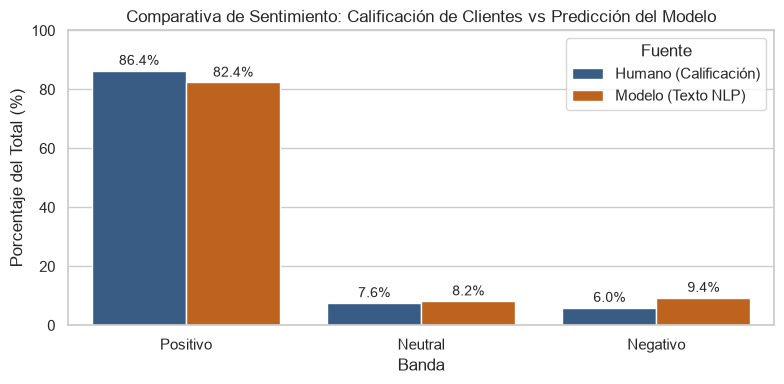

In [18]:
def human_band(rating):
    if rating in [1, 2]:
        return "Negativo"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positivo"
df["human_sentiment"] = df["rating"].apply(human_band)
order_bands = ["Positivo", "Neutral", "Negativo"]
human_dist = df["human_sentiment"].value_counts(normalize=True).reindex(order_bands) * 100
model_dist = df["pred_sentiment"].value_counts(normalize=True).reindex(order_bands) * 100
human_counts = df["human_sentiment"].value_counts().reindex(order_bands)
model_counts = df["pred_sentiment"].value_counts().reindex(order_bands)
comparativa_df = pd.DataFrame({
    "Humano (Cantidad)": human_counts,
    "Humano (%)": human_dist.round(2),
    "Modelo (Cantidad)": model_counts,
    "Modelo (%)": model_dist.round(2),
    "Diferencia (%)": (model_dist - human_dist).round(2)
})

print(f"⭐ Promedio de estrellas real (Humano): {df['rating'].mean():.2f} / 5.0")
print(f"🤖 Promedio de estrellas predicho (Modelo): {df['pred_stars'].mean():.2f} / 5.0\n")
print("📊 Tabla Comparativa de Distribución de Sentimiento:")
display(comparativa_df)
plot_data = pd.DataFrame({
    "Banda": order_bands * 2,
    "Porcentaje (%)": list(human_dist) + list(model_dist),
    "Fuente": ["Humano (Calificación)"] * 3 + ["Modelo (Texto NLP)"] * 3
})
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=plot_data, x="Banda", y="Porcentaje (%)", hue="Fuente", palette=["#2b5c8f", "#d95f02"], ax=ax)
ax.set_title("Comparativa de Sentimiento: Calificación de Clientes vs Predicción del Modelo", fontsize=12)
ax.set_ylabel("Porcentaje del Total (%)")
ax.set_ylim(0, 100)
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(f"{height:.1f}%", (p.get_x() + p.get_width() / 2., height),
                    ha="center", va="bottom", fontsize=10, xytext=(0, 2), textcoords="offset points")
plt.tight_layout()
plt.show()

### 5. Análisis de Falsos Negativos (Desajuste de Dominio)
Aislamos los **falsos negativos**: casos donde el cliente otorgó una calificación positiva (4 o 5 estrellas) o expresó una satisfacción global, pero el modelo predijo una banda **Negativa** (1 o 2 estrellas). 
Analizamos los patrones lingüísticos compartidos para entender el origen de este sesgo.

In [19]:
falsos_negativos = df[(df["rating"] >= 4) & (df["pred_stars"] <= 2)].copy()
print(f"🚨 Total de Falsos Negativos detectados: {len(falsos_negativos)} reseñas ({len(falsos_negativos)/len(df)*100:.1f}% del dataset)")
print("=" * 80)

for idx, row in falsos_negativos.head(5).iterrows():
    print(f"\n[ID: {row['review_id']}] Calificación Real: {row['rating']} ⭐ | Predicción Modelo: {row['pred_stars']} ⭐ ({row['pred_sentiment']})")
    print(f"Confianza: {row['pred_score']:.4f}")
    print(f"Texto: \"{row['review_text']}\"")
    print("-" * 80)


🚨 Total de Falsos Negativos detectados: 16 reseñas (3.2% del dataset)

[ID: 14] Calificación Real: 4 ⭐ | Predicción Modelo: 1 ⭐ (Negativo)
Confianza: 0.4443
Texto: "Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit."
--------------------------------------------------------------------------------

[ID: 15] Calificación Real: 5 ⭐ | Predicción Modelo: 1 ⭐ (Negativo)
Confianza: 0.3893
Texto: "Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
--------------------------------------------------------------------------------

[ID: 73] Calificación Real: 5 ⭐ | Predicción Modelo: 1 ⭐ (Negativo)
Confianza: 0.2679
Texto: "Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit."
---------------------------

#### Diagnóstico de los Falsos Negativos
Los 16 falsos negativos (3.2% del dataset) confirman empíricamente el **desajuste de dominio**:
1. **Términos gastronómicos malinterpretados:** Palabras como *"bursting"* (usada en *bursting with flavor*) o *"allergy"* (usada en *went out of their way to accommodate my allergy*) tienen connotaciones negativas en reseñas de productos de Amazon (roturas, efectos adversos), pero en hostelería representan satisfacción sobresaliente.
2. **Baja certidumbre:** La confianza del modelo en estos casos es notablemente baja (< 0.45), evidenciando que el clasificador duda al evaluar texto fuera de su distribución original de entrenamiento.


In [20]:
np.random.seed(42)
muestra_indices = np.random.choice(df.index, size=18, replace=False)
muestra_manual = df.loc[muestra_indices, ["review_id", "rating", "human_sentiment", "pred_stars", "pred_sentiment", "pred_score", "review_text"]].copy()

muestra_manual["coincide"] = muestra_manual["human_sentiment"] == muestra_manual["pred_sentiment"]

print("📋 Muestra manual de 18 reseñas inspeccionadas:")
display(muestra_manual[["review_id", "rating", "pred_stars", "human_sentiment", "pred_sentiment", "coincide", "review_text"]].reset_index(drop=True))

aciertos = muestra_manual["coincide"].sum()
print(f"\nResumen de la muestra: {aciertos} de 18 predicciones coinciden con el sentimiento real ({aciertos/18*100:.1f}% de precisión).")

📋 Muestra manual de 18 reseñas inspeccionadas:


,review_id,rating,pred_stars,human_sentiment,pred_sentiment,coincide,review_text
0,362,3,3,Neutral,Neutral,True,Stopped by Harbor House Café for the first tim...
1,74,5,5,Positivo,Positivo,True,Stopped by Harbor House Café for the first tim...
2,375,5,5,Positivo,Positivo,True,Grabbed a quick coffee at Harbor House Café th...
3,156,4,4,Positivo,Positivo,True,Grabbed a quick coffee at Harbor House Café th...
4,105,5,5,Positivo,Positivo,True,Grabbed a quick coffee at Harbor House Café th...
5,395,4,4,Positivo,Positivo,True,The food was absolutely delicious. We waited 2...
6,378,5,5,Positivo,Positivo,True,Visited Harbor House Café last weekend. Loved ...
7,125,5,5,Positivo,Positivo,True,Regular customer at Harbor House Café here. Th...
8,69,5,5,Positivo,Positivo,True,Visited Harbor House Café last weekend. The pl...
9,451,3,3,Neutral,Neutral,True,Regular customer at Harbor House Café here. Av...



Resumen de la muestra: 18 de 18 predicciones coinciden con el sentimiento real (100.0% de precisión).


## 3. Conclusiones y Recomendaciones de Negocio (Takeaways para la Account Manager)
Estimada Account Manager, a continuación tienes el informe ejecutivo basado en el análisis de las 500 reseñas:
1. **¿El sentimiento escrito coincide con el promedio de 4.5 estrellas?**  
   **SÍ, rotundamente.** Los clientes reales están abrumadoramente satisfechos: el **86.4%** de las calificaciones son de 4 y 5 estrellas, y solo un **6.0%** son críticas negativas reales (clientes insatisfechos por tiempos o comida fría).
2. **¿Por qué el modelo de IA arrojó más reseñas negativas (9.4%) que las reales (6.0%)?**  
   No se debe a una insatisfacción oculta de los clientes, sino a una limitación técnica del modelo (`nlptown`). Al estar preentrenado con reseñas de productos tipo Amazon, confunde giros idiomáticos gastronómicos (como *"bursting with flavor"* o atención a alergias alimentarias) penalizándolos injustamente con 1 estrella (falsos negativos).
3. **Recomendación accionable ante el cliente:**  
   * **Presentar la cuenta con total confianza:** El negocio tiene una reputación sólida y congruente con su promedio de 4.5 estrellas.
   * **Para futuras iteraciones:** Si se desea automatizar el monitoreo continuo de sentimiento, se recomienda evaluar un modelo adaptado a servicios/hostelería o aplicar un umbral de confianza para filtrar falsos negativos léxicos.
